# MLOps Assignment: Predictive Maintenance Classification
### Starter Notebook

**Domain:** Industrial IoT / Manufacturing
**Task:** Multi-class failure type prediction
**Tools:** Pandera, MLflow, Optuna, Evidently, SHAP

---

## Business Context

A heavy-equipment manufacturer runs 10,000+ machines on the shop floor.
Each machine continuously streams six sensor readings. When a machine fails,
production halts - at a cost of ₹8-15 lakh per hour of downtime.

Your job is to build a full MLOps pipeline that:
1. Validates incoming sensor data before it enters the pipeline (Pandera)
2. Trains and tracks a multi-class failure classifier (MLflow)
3. Tunes hyperparameters and registers the best model (Optuna + MLflow Registry)
4. Monitors the deployed model for distributional shift (Evidently)
5. Explains why the model predicts a specific failure type (SHAP)

**Files provided:**
- `data/train.csv`   - 6,993 labelled sensor readings (historical baseline)
- `data/current.csv` - 1,499 readings from the current stable production batch
- `data/stress.csv`  - 1,499 readings from a heavy-load production period

**Failure classes:**

| Code | Name | Description |
|------|------|-------------|
| 0 | No Failure | Machine operating normally |
| 1 | TWF | Tool Wear Failure |
| 2 | HDF | Heat Dissipation Failure |
| 3 | PWF | Power Failure |
| 4 | OSF | Overstrain Failure |

> Visual anchor: use the generated `eda_distributions.png` early (Section 1.3) to ground your expectations before drift and SHAP interpretation.
> Stress-batch goal: diagnose *why* the model is stale under shifted operating conditions, not to force perfect predictions on `stress.csv`.
> **Submission:** Submit this notebook (`.ipynb`) with all cells executed.
> Do not change the section structure or remove any markdown cells.

## **1. Data Loading, Schema Validation & EDA** <font color=red>[15 marks]</font>

### **1.1** <font color=red>[3 marks]</font> Load the datasets

Load `train.csv`, `current.csv`, and `stress.csv` from the `data/` folder.
Print the shape of each and display the first 5 rows of the training set.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
import os
os.environ['DISABLE_PANDERA_IMPORT_WARNING'] = 'True'

# Load the three datasets
train   = pd.read_csv('data/train.csv')
current = pd.read_csv('data/current.csv')
stress  = pd.read_csv('data/stress.csv')

# Print shapes
print(f'train  : {train.shape}')
print(f'current: {current.shape}')
print(f'stress : {stress.shape}')

CLASS_NAMES = {0: 'No Failure', 1: 'TWF', 2: 'HDF', 3: 'PWF', 4: 'OSF'}

# Display first 5 rows of train
train.head()


train  : (6993, 7)
current: (1499, 7)
stress : (1499, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


### **1.2** <font color=red>[5 marks]</font> Define and apply a Pandera schema

Define a `DataFrameSchema` enforcing the domain constraints below.
Validate `train` and `current` (must pass). Validate `stress` with `lazy=True`.

| Column | Type | Constraint |
|--------|------|------------|
| Type | str | one of L, M, H |
| Air temperature | float | [295.0, 305.0] K |
| Process temperature | float | [305.0, 315.0] K |
| Rotational speed | int64 | [1000, 2900] rpm |
| Torque | float | [3.0, 80.0] Nm |
| Tool wear | int64 | [0, 253] min |
| Failure_Type | int64 | 0, 1, 2, 3, 4 |


> `stress.csv` may still pass schema validation. That is fine: it is designed to be valid but drifted.
> Hint: valid data can still be statistically unusual. Before Section 3, compare the mean of `Rotational speed` in `current` vs `stress`.

In [2]:
import pandera as pa
from pandera import Column, DataFrameSchema, Check

# Define the schema enforcing domain constraints for all 7 columns
schema = DataFrameSchema({
    'Type':                Column(str, Check.isin(['L', 'M', 'H']), nullable=False),
    'Air temperature':     Column(float, Check.in_range(295.0, 305.0, include_min=True, include_max=True), nullable=False),
    'Process temperature': Column(float, Check.in_range(305.0, 315.0, include_min=True, include_max=True), nullable=False),
    'Rotational speed':    Column('int64', Check.in_range(1000, 2900, include_min=True, include_max=True), nullable=False),
    'Torque':              Column(float, Check.in_range(3.0, 80.0, include_min=True, include_max=True), nullable=False),
    'Tool wear':           Column('int64', Check.in_range(0, 253, include_min=True, include_max=True), nullable=False),
    'Failure_Type':        Column('int64', Check.isin([0, 1, 2, 3, 4]), nullable=False),
})

# Converting columns into the required data types
def fix_dtypes(df):
    df = df.copy()
    df['Rotational speed'] = df['Rotational speed'].astype('int64')
    df['Tool wear']        = df['Tool wear'].astype('int64')
    df['Failure_Type']     = df['Failure_Type'].astype('int64')
    return df

train   = fix_dtypes(train)
current = fix_dtypes(current)
stress  = fix_dtypes(stress)

# Validate train and current (must pass)
train_validated   = schema.validate(train)
print("Train dataset validation passed: ", len(train_validated), "rows checked")

current_validated = schema.validate(current)
print("Current dataset validation passed: ", len(current_validated), "rows checked")

# Checking the stress dataset with lazy=True
try:
    stress_validated = schema.validate(stress, lazy=True)
    print("Stress dataset validation passed: ", len(stress_validated), "rows checked")
except pa.errors.SchemaErrors as err:
    print("Stress dataset validation failed with number of errors: ", len(err.failure_cases))
    print(err.failure_cases)

print("\nAverage rotational speed (rpm) for each dataset:")

train_mean = train['Rotational speed'].mean()
current_mean = current['Rotational speed'].mean()
stress_mean = stress['Rotational speed'].mean()

print("Train dataset: ", round(train_mean, 2), "rpm")
print("Current dataset: ", round(current_mean, 2), "rpm")
print("Stress dataset: ", round(stress_mean, 2), "rpm")

print("Difference between Stress and Train datasets: ", round(stress_mean - train_mean, 2), "rpm")


Train dataset validation passed:  6993 rows checked
Current dataset validation passed:  1499 rows checked
Stress dataset validation passed:  1499 rows checked

Average rotational speed (rpm) for each dataset:
Train dataset:  1539.02 rpm
Current dataset:  1530.17 rpm
Stress dataset:  1497.07 rpm
Difference between Stress and Train datasets:  -41.94 rpm


### **1.3** <font color=red>[4 marks]</font> Exploratory Data Analysis

1. Print the class distribution of `Failure_Type`. Is it balanced?
2. Plot the distribution of `Torque` and `Tool wear` split by failure class (failures only).
3. Print the `Type` (L/M/H) distribution.


In [35]:
# class distribution of failure types in the train dataset
class_counts = train['Failure_Type'].value_counts().sort_index()
class_percentage = train ['Failure_Type'].value_counts(normalize=True).sort_index() * 100

print("Failure type distribution: ", class_counts)
print("\nFailure type percentage: ", class_percentage)

print("\nIs the dataset balanced?")

if class_percentage.max() - class_percentage.min() > 20:
    print("No, the dataset is imbalanced")
else:
    print("Yes, the dataset is balanced")

Failure type distribution:  Failure_Type
0    6762
1      30
2      76
3      56
4      69
Name: count, dtype: int64

Failure type percentage:  Failure_Type
0    96.696697
1     0.429000
2     1.086801
3     0.800801
4     0.986701
Name: proportion, dtype: float64

Is the dataset balanced?
No, the dataset is imbalanced


The class distribution shows that the dataset is imbalanced. The number of records with no failure (~97%) is significantly higher compared to the records with actual failures (~3%). Some failure categories also have fewer records than others. This imbalance may affect the machine learning model because it may learn the majority class better than the minority classes.

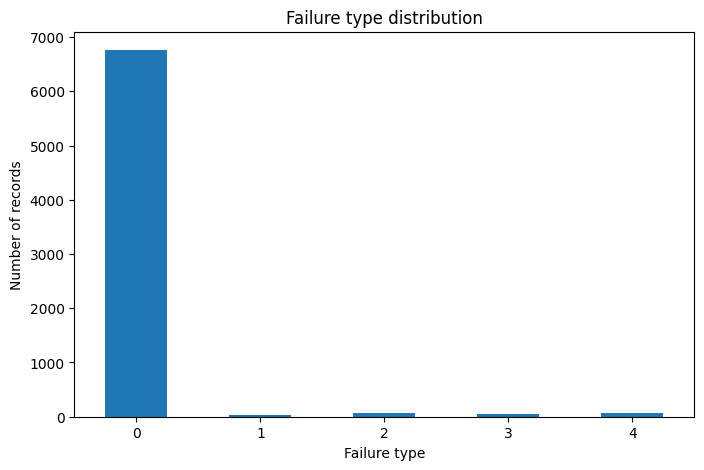

In [4]:
# plotting the failure type distribution
plt.figure(figsize=(8, 5))

class_counts.plot(kind='bar')

plt.title("Failure type distribution")
plt.xlabel("Failure type")
plt.ylabel("Number of records")
plt.xticks(rotation=0)

plt.show()

In [5]:
# selecting the records where failure occured

failures = train[train['Failure_Type'] > 0]

CLASS_NAMES = {
    0: 'No Failure',
    1: 'TWF',
    2: 'HDF',
    3: 'PWF',
    4: 'OSF'
}

failures['Failure_Name'] = failures['Failure_Type'].map(CLASS_NAMES)

print('Failure records:')
print(failures['Failure_Name'].value_counts())

Failure records:
Failure_Name
HDF    76
OSF    69
PWF    56
TWF    30
Name: count, dtype: int64


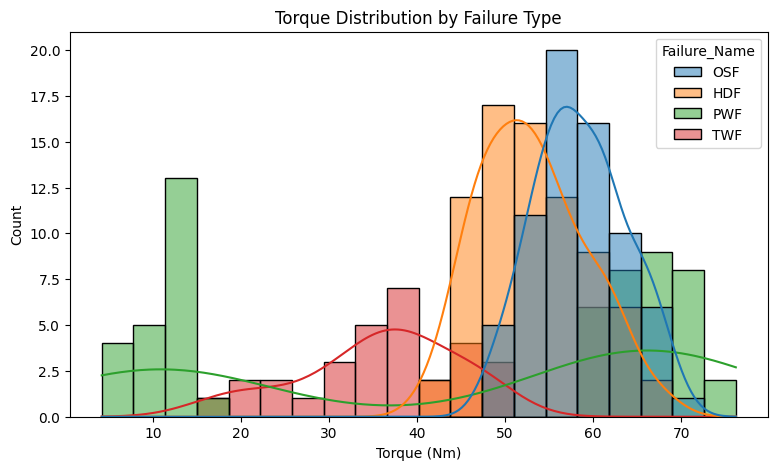

In [6]:

# plotting Torque distribution for different failure types

plt.figure(figsize=(9, 5))

sns.histplot(data=failures,
             x='Torque',
             hue='Failure_Name',
             bins=20,
             kde=True)

plt.title("Torque Distribution by Failure Type")
plt.xlabel("Torque (Nm)")
plt.ylabel("Count")

plt.show()


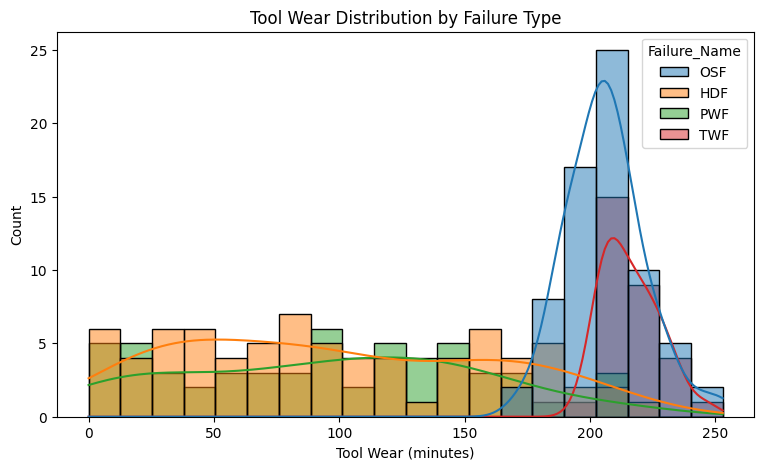

In [7]:

# plotting Tool wear distribution for different failure types

plt.figure(figsize=(9, 5))

sns.histplot(data=failures,
             x='Tool wear',
             hue='Failure_Name',
             bins=20,
             kde=True)

plt.title("Tool Wear Distribution by Failure Type")
plt.xlabel("Tool Wear (minutes)")
plt.ylabel("Count")

plt.show()


I plotted the Torque and Tool wear distributions by considering only records where a failure occurred. This helped me understand how these two features are distributed across different failure types. The histograms helped me identify differences and overlapping patterns.

Product Type Distribution:
Type
L    4213
M    2074
H     706
Name: count, dtype: int64


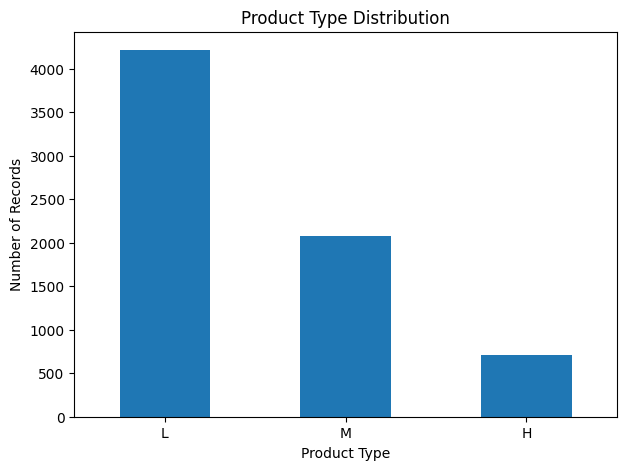

In [8]:

# checking the distribution of Type

type_counts = train['Type'].value_counts()

print("Product Type Distribution:")
print(type_counts)

# plotting the distribution

plt.figure(figsize=(7, 5))

type_counts.plot(kind='bar')

plt.title("Product Type Distribution")
plt.xlabel("Product Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.show()


The distribution of product types (L, M and H) shows how the records are divided among the three product quality categories. This helps understand whether the dataset contains a similar number of records for each product type.

### **1.4** <font color=red>[3 marks]</font> Feature Engineering

Compute the following derived features for all three datasets:

**Mechanical power** (Watts):
$$P = \text{Torque} \times \frac{\text{Rotational speed} \times 2\pi}{60}$$

**Temperature differential**:
$$\Delta T = \text{Process temperature} - \text{Air temperature}$$

Print the mean of each new feature grouped by `Failure_Type`.


In [9]:
def engineer_features(df):
    df = df.copy()

    # calculating power using torque and rotational speed
    df['Power_W']   = df['Torque'] * (df['Rotational speed'] * 2 * np.pi / 60)

    # calculating the difference between Process temperature and Air temperature
    df['Temp_diff'] = df['Process temperature'] - df['Air temperature']

    return df

# applying the function to all three datasets
train   = engineer_features(train)
current = engineer_features(current)
stress  = engineer_features(stress)

# checking the average values of new features for each failure type
grouped_means = train.groupby('Failure_Type')[['Power_W', 'Temp_diff']].mean()

# adding failure names to the output
grouped_means['Failure_Name'] = grouped_means.index.map(CLASS_NAMES)

print('Average Power and Temperature Difference for each failure type:')
print(round(grouped_means,2))

Average Power and Temperature Difference for each failure type:
              Power_W  Temp_diff Failure_Name
Failure_Type                                 
0             6248.24      10.01   No Failure
1             5763.09       9.97          TWF
2             7403.55       8.23          HDF
3             6664.38       9.82          PWF
4             8216.07      10.07          OSF


## **2. Experiment Tracking & Model Selection** <font color=red>[15 marks]</font>

### **2.1** <font color=red>[2 marks]</font> Setup: features, split, SMOTE

Use the features below. Apply a stratified 80/20 train-val split (random_state=42).
Apply SMOTE to the training split only. Print the post-SMOTE class distribution.

```
FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
```

> In a markdown cell below the code, explain in 2–3 sentences why SMOTE is applied
> only to the training split and not the validation set.


Encode the Type column

In [ ]:
from sklearn.preprocessing import LabelEncoder
import joblib

# converting type values into numbers
le = LabelEncoder()
train['Type_enc'] = le.fit_transform(train['Type'])
current['Type_enc'] = le.transform(current['Type'])
stress['Type_enc'] = le.transform(stress['Type'])

# saving the encoder for future use
joblib.dump(le, 'label_encoder.pkl')

print("Type encoding complete.")
print("Encoding values: ", le.classes_)

Type encoding completed
Encoding values:  ['H' 'L' 'M']


Select features and target variable

In [11]:
train.describe()

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type,Power_W,Temp_diff,Type_enc
count,6993.000000,6993.000000,6993.000000,6993.000000,6993.000000,6993.000000,6993.000000,6993.000000,6993.000000
mean,300.011626,310.004891,1539.017589,39.995796,107.679108,0.089518,6281.464568,9.993265,1.195624
std,2.004642,1.481363,179.909994,9.977137,63.818988,0.519357,1067.209431,1.000721,0.599436
min,295.300000,305.700000,1168.000000,4.200000,0.000000,0.000000,1264.051220,7.600000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,52.000000,0.000000,5561.770914,9.200000,1.000000
50%,300.100000,310.100000,1504.000000,40.100000,107.000000,0.000000,6266.890913,9.800000,1.000000
75%,301.500000,311.100000,1614.000000,46.800000,163.000000,0.000000,7013.417104,11.000000,2.000000
max,304.500000,313.800000,2874.000000,76.200000,253.000000,4.000000,10112.074658,12.100000,2.000000


In [12]:

# selecting the columns for the model training
FEATURES = [
    'Type_enc',
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
    'Power_W',
    'Temp_diff'
]

# separating input features and target column

X = train[FEATURES]
y = train['Failure_Type']

print('Input features shape: ', X.shape)
print('Target variable shape: ', y.shape)


Input features shape:  (6993, 8)
Target variable shape:  (6993,)


Split training and validation data

In [13]:

from sklearn.model_selection import train_test_split

# splitting the data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape: ", X_train.shape)
print("Validation data shape: ", X_val.shape)

# checking the failure type distribution before SMOTE

print("\nClass distribution before SMOTE:")

print(y_train.value_counts().sort_index())


Training data shape:  (5594, 8)
Validation data shape:  (1399, 8)

Class distribution before SMOTE:
Failure_Type
0    5409
1      24
2      61
3      45
4      55
Name: count, dtype: int64


Apply SMOTE to balance the training data

In [14]:
from imblearn.over_sampling import SMOTE

# applying SMOTE to the training data
smote = SMOTE(k_neighbors=3, random_state=42)

X_res,y_res = smote.fit_resample(X_train, y_train)

# checking the class distribution after SMOTE
print('Class distribution after SMOTE: ')
print(y_res.value_counts().sort_index())
print("\nTotal training records after SMOTE: ", len(y_res))

Class distribution after SMOTE: 
Failure_Type
0    5409
1    5409
2    5409
3    5409
4    5409
Name: count, dtype: int64

Total training records after SMOTE:  27045


### Why SMOTE is applied only to the training data

SMOTE is applied only to the training data because we want to avoid data leakage. If we apply SMOTE before splitting the data, synthetic records could be created using information from both training and validation datasets.

The validation data should contain the original records without any changes so that we can check how well the model performs on unseen data. In real-world situations, machine sensor data may also have an imbalanced distribution, with some failure types occurring less frequently than others.

By keeping the validation data unchanged, we can get a more realistic understanding of the model's performance using metrics such as Macro F1, Weighted F1 and individual class F1 scores.

### **2.2** <font color=red>[8 marks]</font> Train and log 4 models with MLflow

Train and evaluate:
- Logistic Regression
- Random Forest (n_estimators=100)
- XGBoost (n_estimators=100)
- LightGBM (n_estimators=100)

MLflow experiment name: `PredMaint_ModelSelection`

For each run log: `model` (param), `macro_f1`, `weighted_f1`, `accuracy` (metrics),
and per-class F1 for all 5 classes. Print a comparison table. Pick the best model by macro F1.


Import libraries and configure MLflow

In [15]:
import mlflow
import mlflow.sklearn
import sqlalchemy

import pandas as pd

from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# setting up MLflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('PredMaint_ModelSelection')

print('MLflow experiment created successfully')

MLflow experiment created successfully


Define the four ML models

In [16]:

# creating the machine learning models
models = {

    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=2000, random_state=42, class_weight='balanced'))
    ]),

    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'
    ),

    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss', verbosity=0
    ),

    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, class_weight='balanced', verbose=-1
    )

}

print("Four models are ready for training")


Four models are ready for training


Train, evaluate and log the models

In [17]:

# list of failure classes

CLASS_LIST = [0, 1, 2, 3, 4]

# to store model results

results = {}

# training and evaluating each model

for name, model in models.items():

    print("\nTraining:", name)

    # starting an MLflow run
    with mlflow.start_run(run_name=name):

        # training the model
        model.fit(X_res, y_res)

        # predicting using validation data
        y_pred = model.predict(X_val)

        # calculating evaluation metrics
        macro_f1 = f1_score(y_val, y_pred, average='macro', zero_division=0)

        weighted_f1 = f1_score(y_val, y_pred, average='weighted', zero_division=0)

        accuracy = accuracy_score(y_val, y_pred)

        # logging model name and evaluation results
        mlflow.log_param('model', name)

        mlflow.log_metric('macro_f1', macro_f1)
        mlflow.log_metric('weighted_f1', weighted_f1)
        mlflow.log_metric('accuracy', accuracy)

        # calculating F1 score for each failure class
        class_f1 = f1_score(
            y_val,
            y_pred,
            labels=CLASS_LIST,
            average=None,
            zero_division=0
        )

        # saving individual class F1 scores
        for i in range(len(CLASS_LIST)):

            class_name = CLASS_NAMES[CLASS_LIST[i]].replace(' ', '_')

            mlflow.log_metric('f1_' + class_name, float(class_f1[i]))

        # saving the trained model in MLflow
        mlflow.sklearn.log_model(
            model,
            artifact_path='model',
            input_example=X_val.iloc[:5]
        )

        # storing results for comparison
        results[name] = {
            'macro_f1': macro_f1,
            'weighted_f1': weighted_f1,
            'accuracy': accuracy
        }

        # adding individual class scores to results
        for i in range(len(CLASS_LIST)):

            class_name = CLASS_NAMES[CLASS_LIST[i]]

            results[name]['F1_' + class_name] = class_f1[i]

        print("Macro F1:", round(macro_f1, 4))
        print("Weighted F1:", round(weighted_f1, 4))
        print("Accuracy:", round(accuracy, 4))

print("\nAll four models have been trained and evaluated.")



Training: Logistic Regression


Macro F1: 0.5312
Weighted F1: 0.9328
Accuracy: 0.9042

Training: Random Forest


Macro F1: 0.7355
Weighted F1: 0.9855
Accuracy: 0.985

Training: XGBoost


  File "c:\Github\projects\mlops-projects-portfolio\mlops\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\vishn\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vishn\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\vishn\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Macro F1: 0.7481
Weighted F1: 0.9851
Accuracy: 0.9843

Training: LightGBM


Macro F1: 0.7296
Weighted F1: 0.9851
Accuracy: 0.9843

All four models have been trained and evaluated.


Compare models and identify the best model

In [18]:

# creating a comparison table

comparison_df = pd.DataFrame(results).T

# sorting models based on Macro F1 score
comparison_df = comparison_df.sort_values(
    by='macro_f1',
    ascending=False
)

print("Model Comparison Results:")
print(comparison_df.round(4))


# finding the best model

best_model = comparison_df['macro_f1'].idxmax()

best_score = comparison_df.loc[best_model, 'macro_f1']

print("\nBest Model:", best_model)
print("Best Macro F1 Score:", round(best_score, 4))


Model Comparison Results:
                     macro_f1  weighted_f1  accuracy  F1_No Failure  F1_TWF  \
XGBoost                0.7481       0.9851    0.9843         0.9922  0.1333   
Random Forest          0.7355       0.9855    0.9850         0.9926  0.0000   
LightGBM               0.7296       0.9851    0.9843         0.9922  0.0000   
Logistic Regression    0.5312       0.9328    0.9042         0.9483  0.1449   

                     F1_HDF  F1_PWF  F1_OSF  
XGBoost              0.9655  0.8800  0.7692  
Random Forest        0.9286  0.9565  0.8000  
LightGBM             0.9655  0.8333  0.8571  
Logistic Regression  0.4545  0.4583  0.6500  

Best Model: XGBoost
Best Macro F1 Score: 0.7481


### 2.2 Model Training and Comparison using MLflow

I trained four machine learning models: Logistic Regression, Random Forest, XGBoost and LightGBM. All models were trained using the SMOTE-resampled training data and evaluated using the validation dataset.

The evaluation results showed that XGBoost achieved the highest Macro F1 score of 0.7481, followed by Random Forest with 0.7355 and LightGBM with 0.7296. Logistic Regression achieved a Macro F1 score of 0.5312.

Random Forest achieved the highest accuracy of 98.50%, while XGBoost achieved 98.43%. However, I selected XGBoost as the best model because it had the highest Macro F1 score.

One important observation was that all four models struggled to identify TWF (Tool Wear Failure). Random Forest and LightGBM had an F1 score of zero for this class, while XGBoost achieved 0.1333. On the other hand, the models performed well in identifying No Failure and other failure categories.

I used MLflow to track the model parameters, evaluation metrics and trained model artefacts. This helped me compare the four models and select XGBoost for further evaluation.

### **2.3** <font color=red>[5 marks]</font> Optuna tuning + MLflow Model Registry

Run an Optuna study (30 trials, `TPESampler(seed=42)`) tuning XGBoost hyperparameters.
Optimise for `macro_f1` on `X_val`.

MLflow experiment: `PredMaint_Optuna`

Register the best model as `PredMaint_XGBoost` and promote it to the `production` alias.
Print the improvement in macro F1 over the baseline XGBoost.


Import libraries and configure MLflow

In [19]:
import optuna
import joblib

from mlflow.tracking import MlflowClient

# Setting up the Optuna experiment

mlflow.set_experiment('PredMaint_Optuna')

# Hiding unnecessary Optuna messages

optuna.logging.set_verbosity(optuna.logging.WARNING)

print("Optuna experiment is ready")

Optuna experiment is ready


Define the objective function and hyperparameters

In [20]:

# Defining the objective function for Optuna

def objective(trial):

    # Selecting different hyperparameter values

    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight': trial.suggest_float('min_child_weight', 1.0, 10.0),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 2.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'random_state': 42,
        'eval_metric': 'mlogloss',
        'verbosity': 0
    }

    # Creating and training the XGBoost model

    model = XGBClassifier(**params)

    model.fit(X_res, y_res)

    # Predicting on validation data

    y_pred = model.predict(X_val)

    # Calculating Macro F1 score

    score = f1_score(y_val, y_pred, average='macro', zero_division=0)

    return score


Run Optuna study (30 trials)

In [21]:

# Creating an Optuna study

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Running 30 trials

study.optimize(objective, n_trials=30)


# Displaying the best results

print("Best Trial Number:", study.best_trial.number)

print("Best Macro F1 Score:", round(study.best_value, 4))

print("\nBest Hyperparameters:")

for key, value in study.best_params.items():
    print(key, ":", value)


Best Trial Number: 29
Best Macro F1 Score: 0.761

Best Hyperparameters:
n_estimators : 462
max_depth : 4
learning_rate : 0.08853874505145662
min_child_weight : 6.83456102352091
subsample : 0.6473544266888274
colsample_bytree : 0.8745534255937363
gamma : 0.47778375377411253
reg_alpha : 1.9045113036901531e-07
reg_lambda : 0.0007066255503193089


Train and evaluate the best XGBoost model

In [22]:

# Creating the final model using the best hyperparameters

best_params = study.best_params.copy()

best_params['random_state'] = 42
best_params['eval_metric'] = 'mlogloss'
best_params['verbosity'] = 0

best_model = XGBClassifier(**best_params)

# Training the final model

best_model.fit(X_res, y_res)

# Predicting on validation data

y_val_pred = best_model.predict(X_val)


# Calculating evaluation metrics

tuned_macro_f1 = f1_score(
    y_val, y_val_pred, average='macro', zero_division=0
)

tuned_weight_f1 = f1_score(
    y_val, y_val_pred, average='weighted', zero_division=0
)

tuned_accuracy = accuracy_score(y_val, y_val_pred)


# Calculating F1 score for each failure class

tuned_per_class = f1_score(
    y_val,
    y_val_pred,
    labels=CLASS_LIST,
    average=None,
    zero_division=0
)


# Displaying the results

print("Tuned XGBoost Results")
print("Macro F1:", round(tuned_macro_f1, 4))
print("Weighted F1:", round(tuned_weight_f1, 4))
print("Accuracy:", round(tuned_accuracy, 4))

print("\nIndividual Class F1 Scores:")

for i in range(len(CLASS_LIST)):
    print(CLASS_NAMES[CLASS_LIST[i]], ":", round(tuned_per_class[i], 4))


Tuned XGBoost Results
Macro F1: 0.761
Weighted F1: 0.9853
Accuracy: 0.9828

Individual Class F1 Scores:
No Failure : 0.9915
TWF : 0.1053
HDF : 0.9655
PWF : 0.8462
OSF : 0.8966


Log, register and promote the model in MLflow

In [23]:

# Saving the best model in MLflow

with mlflow.start_run(run_name='XGBoost_Optuna_Best'):

    # Logging model information

    mlflow.log_param('model', 'XGBoost_Optuna')

    mlflow.log_params(study.best_params)

    # Logging evaluation metrics

    mlflow.log_metric('macro_f1', tuned_macro_f1)
    mlflow.log_metric('weighted_f1', tuned_weight_f1)
    mlflow.log_metric('accuracy', tuned_accuracy)

    # Logging individual class F1 scores

    for i in range(len(CLASS_LIST)):

        class_name = CLASS_NAMES[CLASS_LIST[i]].replace(' ', '_')

        mlflow.log_metric(
            'f1_' + class_name,
            float(tuned_per_class[i])
        )

    # Saving and registering the model

    model_info = mlflow.sklearn.log_model(
        best_model,
        artifact_path='model',
        input_example=X_val.iloc[:5],
        registered_model_name='PredMaint_XGBoost'
    )


# Getting the registered model version

client = MlflowClient()

model_version = model_info.registered_model_version

# Assigning production alias to the registered model

client.set_registered_model_alias(
    'PredMaint_XGBoost',
    'production',
    str(model_version)
)

print("Model registered successfully")
print("Model name: PredMaint_XGBoost")
print("Model version:", model_version)
print("Model alias: production")


Registered model 'PredMaint_XGBoost' already exists. Creating a new version of this model...
Created version '3' of model 'PredMaint_XGBoost'.


Model registered successfully
Model name: PredMaint_XGBoost
Model version: 3
Model alias: production


Save the model and compare Macro F1 scores

In [24]:

# Saving the trained model and label encoder

joblib.dump(best_model, 'best_model.pkl')
joblib.dump(le, 'label_encoder.pkl')


# Getting the baseline XGBoost Macro F1 score

baseline_xgb_f1 = results['XGBoost']['macro_f1']

# Calculating the improvement

improvement = tuned_macro_f1 - baseline_xgb_f1

improvement_percentage = (improvement / baseline_xgb_f1) * 100


# Displaying the comparison

print("\nXGBoost Model Comparison")

print("Baseline Macro F1:", round(baseline_xgb_f1, 4))

print("Tuned Macro F1:", round(tuned_macro_f1, 4))

print("Macro F1 Improvement:", round(improvement, 4))

print("Improvement Percentage:", round(improvement_percentage, 2), "%")

print("\nBest model is registered as PredMaint_XGBoost")
print("Production alias:", "production")

print("\nModel and label encoder saved successfully")



XGBoost Model Comparison
Baseline Macro F1: 0.7481
Tuned Macro F1: 0.761
Macro F1 Improvement: 0.0129
Improvement Percentage: 1.73 %

Best model is registered as PredMaint_XGBoost
Production alias: production

Model and label encoder saved successfully


## **3. Drift Detection & Monitoring** <font color=red>[10 marks]</font>

> Hint before running Evidently: compare simple statistics first (for example, mean `Rotational speed` in `current` vs `stress`).
> Reminder: passing Pandera only means values are valid; it does **not** mean the batch is in-distribution.
> Section objective: identify why the deployed model is stale on stress conditions.

### **3.1** <font color=red>[4 marks]</font> Evidently — current batch

Reference: `train[FEAT_COLS]` | Current: `current[FEAT_COLS]`

```
FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']
```

Run `DataDriftPreset`. Save HTML to `drift_current.html`.
Report: drift detected? How many features drifted?


Select features and compare basic statistics

In [25]:

# Selecting the features for drift detection

FEAT_COLS = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear'
]


# Comparing average values across datasets

stats_comp = pd.DataFrame({
    'Train': train[FEAT_COLS].mean(),
    'Current': current[FEAT_COLS].mean(),
    'Stress': stress[FEAT_COLS].mean()
})

print("Average Feature Values Across Datasets:")
print(stats_comp.round(2))


Average Feature Values Across Datasets:
                       Train  Current   Stress
Air temperature       300.01   299.92   300.05
Process temperature   310.00   310.00   310.01
Rotational speed     1539.02  1530.17  1497.07
Torque                 40.00    40.22    44.72
Tool wear             107.68   108.20   148.87


Run Evidently Data Drift Detection

In [26]:

from evidently.legacy.report import Report
from evidently.legacy.metric_preset import DataDriftPreset

# Creating the data drift report

report_current = Report(metrics=[DataDriftPreset()])

# Comparing training data with current data

report_current.run(
    reference_data=train[FEAT_COLS],
    current_data=current[FEAT_COLS]
)

# Saving the report as an HTML file

report_current.save_html('drift_current.html')

print("Data drift report generated successfully")
print("Report saved as drift_current.html")


Data drift report generated successfully
Report saved as drift_current.html


Display the drift results

In [27]:

# Getting the results from the Evidently report

report_results = report_current.as_dict()

# Extracting dataset drift information

for metric in report_results['metrics']:

    if metric['metric'] == 'DatasetDriftMetric':
        drift_summary = metric['result']

    if metric['metric'] == 'DataDriftTable':
        drift_table = metric['result']['drift_by_columns']


# Displaying overall drift results

print("Data Drift Summary - Current vs Train")

print("Dataset Drift Detected:", drift_summary['dataset_drift'])

print("Number of Drifted Features:",
      drift_summary['number_of_drifted_columns'],
      "out of",
      drift_summary['number_of_columns'])


# Displaying individual feature drift results

print("\nIndividual Feature Drift Results:")

for col in FEAT_COLS:

    feature_result = drift_table[col]

    print("\nFeature:", col)
    print("Drift Detected:", feature_result['drift_detected'])
    print("Statistical Test:", feature_result['stattest_name'])
    print("Drift Score:", round(feature_result['drift_score'], 4))
    print("Train Mean:", round(train[col].mean(), 2))
    print("Current Mean:", round(current[col].mean(), 2))


Data Drift Summary - Current vs Train
Dataset Drift Detected: False
Number of Drifted Features: 0 out of 5

Individual Feature Drift Results:

Feature: Air temperature
Drift Detected: False
Statistical Test: Wasserstein distance (normed)
Drift Score: 0.0548
Train Mean: 300.01
Current Mean: 299.92

Feature: Process temperature
Drift Detected: False
Statistical Test: Wasserstein distance (normed)
Drift Score: 0.0244
Train Mean: 310.0
Current Mean: 310.0

Feature: Rotational speed
Drift Detected: False
Statistical Test: Wasserstein distance (normed)
Drift Score: 0.0526
Train Mean: 1539.02
Current Mean: 1530.17

Feature: Torque
Drift Detected: False
Statistical Test: Wasserstein distance (normed)
Drift Score: 0.04
Train Mean: 40.0
Current Mean: 40.22

Feature: Tool wear
Drift Detected: False
Statistical Test: Wasserstein distance (normed)
Drift Score: 0.0181
Train Mean: 107.68
Current Mean: 108.2


### 3.1 Evidently – Current Batch

I used Evidently to compare the training dataset with the current dataset. The results showed that no significant data drift was detected.

None of the five selected features (Air temperature, Process temperature, Rotational speed, Torque and Tool wear) showed drift.

This indicates that the current data distribution is still similar to the training data. Therefore, the existing model appears suitable for the current operating conditions.

The HTML report was generated and saved as `drift_current.html` for further analysis.

### **3.2** <font color=red>[4 marks]</font> Evidently - stress batch

Repeat for `stress.csv`. Use `ColumnDriftMetric` for individual feature scores.
Save as `drift_stress.html`.
Print a table: feature | drift detected | Wasserstein score | ref mean | current mean | delta.

Focus question: this section is about diagnosing *staleness risk* (what shifted and why), not "making stress predictions look good."

Import libraries and prepare the drift metrics

In [28]:

from evidently.legacy.report import Report
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

# Creating drift metrics for each feature

metrics = [DatasetDriftMetric()]

for col in FEAT_COLS:
    metrics.append(ColumnDriftMetric(column_name=col))

print("Drift metrics are ready")


Drift metrics are ready


Run Evidently on the stress dataset

In [29]:

# Creating the Evidently report

report_stress = Report(metrics=metrics)

# Comparing training data with stress data

report_stress.run(
    reference_data=train[FEAT_COLS],
    current_data=stress[FEAT_COLS]
)

# Saving the report

report_stress.save_html('drift_stress.html')

print("Stress data drift report generated successfully")


Stress data drift report generated successfully


Display drift results for each feature

In [30]:

# Getting the results from the Evidently report

report_results = report_stress.as_dict()

# Extracting overall dataset drift information

for metric in report_results['metrics']:

    if metric['metric'] == 'DatasetDriftMetric':
        drift_summary = metric['result']


# Creating a table for individual feature results

stress_results = []

for metric in report_results['metrics']:

    if metric['metric'] == 'ColumnDriftMetric':

        result = metric['result']

        col = result['column_name']

        # Calculating average values

        ref_mean = train[col].mean()
        current_mean = stress[col].mean()

        difference = current_mean - ref_mean

        # Storing the results

        stress_results.append({
            'Feature': col,
            'Drift Detected': result['drift_detected'],
            'Wasserstein Score': round(result['drift_score'], 4),
            'Ref Mean': round(ref_mean, 2),
            'Current Mean': round(current_mean, 2),
            'Delta': round(difference, 2)
        })


# Converting results into a DataFrame

stress_drift_df = pd.DataFrame(stress_results)

# Displaying the results

print("Stress Dataset Drift Summary")

print("\nDataset Drift Detected:",
      drift_summary['dataset_drift'])

print("Number of Drifted Features:",
      drift_summary['number_of_drifted_columns'],
      "out of",
      drift_summary['number_of_columns'])

print("\nIndividual Feature Drift Results:")

print(stress_drift_df.to_string(index=False))

print("\nReport saved as drift_stress.html")


Stress Dataset Drift Summary

Dataset Drift Detected: True
Number of Drifted Features: 3 out of 5

Individual Feature Drift Results:
            Feature  Drift Detected  Wasserstein Score  Ref Mean  Current Mean  Delta
    Air temperature           False             0.0344    300.01        300.05   0.04
Process temperature           False             0.0377    310.00        310.01   0.00
   Rotational speed            True             0.2354   1539.02       1497.07 -41.94
             Torque            True             0.4739     40.00         44.72   4.73
          Tool wear            True             0.6455    107.68        148.87  41.19

Report saved as drift_stress.html


### **3.3** <font color=red>[2 marks]</font> Retraining decision

Answer the following in a markdown cell:
1. Which features drifted in the stress batch?
2. Cross-referencing with your SHAP results (Section 4) ? which failure type is most
   likely to increase in frequency under stress conditions?
3. Should the model be retrained? Justify with evidence from Sections 3.1, 3.2, and 4.

Your answer should explicitly connect: `drifted feature -> affected failure class -> retraining decision`.

## 3.3 – Retraining Decision

**1. Which features drifted in the stress batch?**

Data drift was detected in 3 out of 5 features:

- Tool wear increased by 38.3% (107.68 to 148.87).
- Torque increased by 11.8% (40.00 to 44.72).
- Rotational speed decreased by approximately 41.94 rpm.

Air temperature and Process temperature did not show significant drift.

**2. Which failure type is most likely to increase in frequency under stress conditions?**

OSF is the main potential concern because Tool wear is its top SHAP feature and Torque is its second most important feature. Both showed drift in the stress batch.

TWF could also be affected because Tool wear is its top SHAP feature. PWF may be affected by changes in Torque and Rotational speed, while Rotational speed is also an important feature for HDF.

**3. Should the model be retrained?**

The current batch showed no significant drift, so the existing model appears suitable for current operating conditions.

However, the stress batch showed drift in 3 out of 5 features, including important features used by the model. I recommend collecting labelled stress data and evaluating the existing model. If its prediction performance has dropped, we should retrain it using the new data and validate it before deployment.

**Overall, Tool wear and Torque drift make OSF a key potential concern under stress conditions. The model should be monitored closely, and retraining should depend on its performance on the new data.**

## **4. Explainability & Insights** <font color=red>[5 marks]</font>

> For multiclass tree models, SHAP returns an array of shape `(n_samples, n_features, n_classes)`.
>
> **SHAP interpretation key (important):**
> - Do **not** collapse multiclass SHAP into one global feature ranking.
> - Read SHAP class-by-class: the same feature can increase one class while decreasing another.
> - Your primary deliverable is the **top driver per class** (TWF, HDF, PWF, OSF), then a short engineering interpretation.

### **4.1** <font color=red>[3 marks]</font> SHAP analysis per failure class

Load `best_model.pkl`. Use `shap.TreeExplainer` on `train[FEATURES]`.
Plot mean |SHAP| bar charts for TWF, HDF, PWF, OSF (4 subplots). Save as `shap_per_class.png`.
Print the top driver for each failure class.

Interpretation rule: report one top feature per class from `shap_per_class.png`; avoid a single cross-class "global winner."

Load the model and calculate SHAP values

In [31]:
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the best model saved earlier
best_model = joblib.load('best_model.pkl')

# Calculate SHAP values using the training data
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(train[FEATURES])

# Convert SHAP values into an array
shap_arr = np.array(shap_values)

# Adjust the shape if SHAP returns classes as the first dimension
if shap_arr.ndim == 3 and shap_arr.shape[0] == len(CLASS_LIST):
    shap_arr = np.transpose(shap_arr, (1, 2, 0))

print("SHAP array shape:", shap_arr.shape)

SHAP array shape: (6993, 8, 5)


Calculate feature importance for each failure class

In [32]:
# Failure classes: TWF, HDF, PWF and OSF
failure_classes = [1, 2, 3, 4]

# Store the top feature and importance for each class
top_drivers = {}
shap_summary_table = {}

for c in failure_classes:

    class_name = CLASS_NAMES[c]

    # Calculate average absolute SHAP value for each feature
    mean_abs_shap = np.abs(shap_arr[:, :, c]).mean(axis=0)

    # Create a sorted list of feature importance
    shap_series = pd.Series(mean_abs_shap, index=FEATURES)
    shap_series = shap_series.sort_values(ascending=False)

    # Store the results
    shap_summary_table[class_name] = shap_series

    # Get the most important feature for this class
    top_drivers[class_name] = (shap_series.index[0], shap_series.iloc[0])

print("Top SHAP Driver per Failure Class:")

for class_name, (feature, value) in top_drivers.items():
    print(f"{class_name} -> {feature} (Mean |SHAP| = {value:.4f})")

Top SHAP Driver per Failure Class:
TWF -> Tool wear (Mean |SHAP| = 3.6554)
HDF -> Temp_diff (Mean |SHAP| = 3.1523)
PWF -> Power_W (Mean |SHAP| = 3.8403)
OSF -> Tool wear (Mean |SHAP| = 2.8020)


Plot the SHAP importance charts

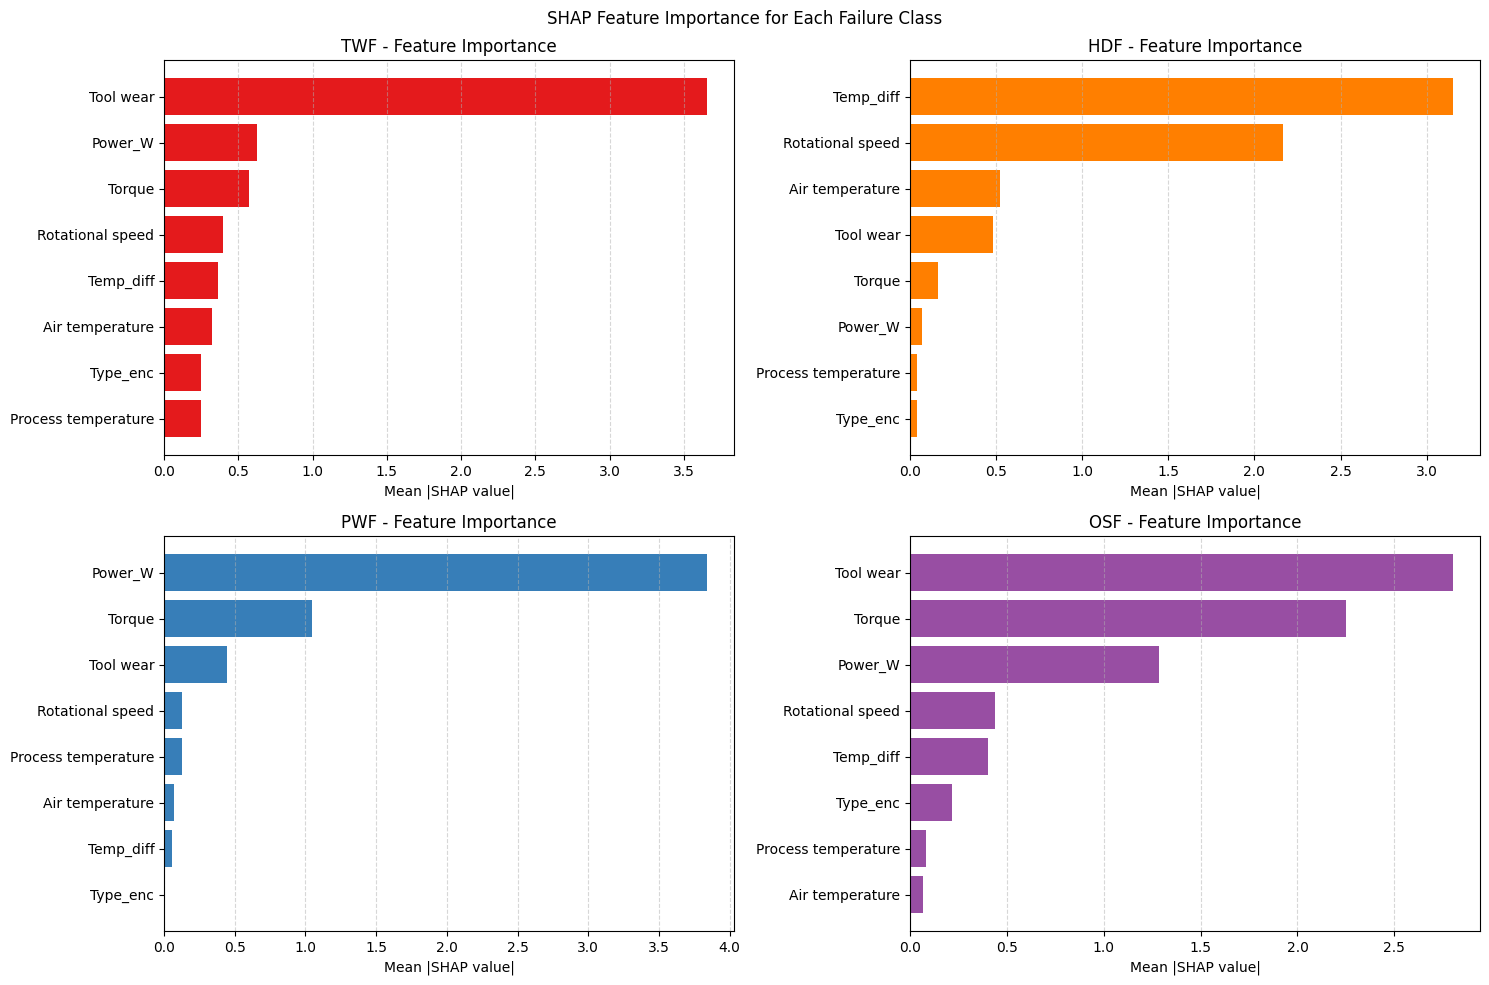

In [33]:
class_colors = {
    1: '#e41a1c',
    2: '#ff7f00',
    3: '#377eb8',
    4: '#984ea3'
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, c in enumerate(failure_classes):

    class_name = CLASS_NAMES[c]
    shap_series = shap_summary_table[class_name].sort_values()

    # Plot feature importance
    axes[idx].barh(
        shap_series.index,
        shap_series.values,
        color=class_colors[c]
    )

    axes[idx].set_title(f"{class_name} - Feature Importance")
    axes[idx].set_xlabel("Mean |SHAP value|")
    axes[idx].grid(axis='x', linestyle='--', alpha=0.5)

plt.suptitle("SHAP Feature Importance for Each Failure Class")
plt.tight_layout()

# Save the chart
plt.savefig('shap_per_class.png', dpi=150, bbox_inches='tight')

plt.show()

Display the complete importance table

In [34]:
# Display feature importance for all failure classes
shap_table = pd.DataFrame(shap_summary_table)

print("Mean Absolute SHAP Values:")
print(shap_table.round(4))

print("\nTop Driver for Each Failure Class:")

for class_name, (feature, value) in top_drivers.items():
    print(f"{class_name}: {feature} ({value:.4f})")

print("\nChart saved as shap_per_class.png")

Mean Absolute SHAP Values:
                        TWF     HDF     PWF     OSF
Air temperature      0.3217  0.5211  0.0703  0.0672
Power_W              0.6278  0.0693  3.8403  1.2879
Process temperature  0.2460  0.0430  0.1242  0.0826
Rotational speed     0.3949  2.1667  0.1296  0.4376
Temp_diff            0.3615  3.1523  0.0568  0.4048
Tool wear            3.6554  0.4818  0.4457  2.8020
Torque               0.5745  0.1648  1.0432  2.2495
Type_enc             0.2483  0.0382  0.0003  0.2183

Top Driver for Each Failure Class:
TWF: Tool wear (3.6554)
HDF: Temp_diff (3.1523)
PWF: Power_W (3.8403)
OSF: Tool wear (2.8020)

Chart saved as shap_per_class.png


### **4.2** <font color=red>[2 marks]</font> Engineering insight

Answer in this markdown cell:

1. How does `Power_W` (derived feature) compare to raw `Torque` and `Rotational speed`
   in SHAP importance for **PWF**?
2. How does `Temp_diff` rank for **HDF** vs other failure types?
3. In 2-3 sentences, describe the physical mechanism behind each failure type based on SHAP.

Suggested structure for your actionable recommendation (used again in Section 5.1.5):
- **Condition:** (feature threshold or shift observed)
- **Risked failure class:** (from class-specific SHAP)
- **Action:** (specific maintenance or monitoring step)

## 4.2 – Engineering Insight

**1. Power_W compared with Torque and Rotational speed for PWF**

Power_W is the most important feature for PWF, with a SHAP value of 3.8403. Torque ranks second (1.0432), while Rotational speed ranks fourth (0.1296). This shows that the derived Power_W feature provides much stronger information to the model than either raw feature individually.

**2. Temp_diff ranking for HDF**

Temp_diff ranks first for HDF, with a SHAP value of 3.1523. It has a much lower importance for TWF (5th), PWF (7th) and OSF (5th). This indicates that the temperature difference between process and air temperature is particularly important for predicting HDF.

**3. Physical mechanism behind each failure type**

- **TWF:** Excessive tool wear can damage the cutting tool and eventually cause failure.
- **HDF:** A lower temperature difference between process and air temperature may indicate poor heat dissipation. This can cause heat-related problems in the machine.
- **PWF:** Changes in torque and rotational speed affect machine power. Power_W captures their combined effect and is the strongest feature for this failure type.
- **OSF:** High mechanical load and tool wear can increase stress on the tool, potentially leading to failure.

**Actionable Recommendation**

- **Condition:** Tool wear and torque increase, while rotational speed decreases.
  **Risked failure class:** OSF and TWF.
  **Action:** Monitor tool wear and torque regularly, and schedule tool inspection or replacement when wear approaches the operating limit.

- **Condition:** A lower-than-normal temperature difference.
  **Risked failure class:** HDF.
  **Action:** Monitor temperature differences and inspect the machine's cooling system when unusual changes are observed.

- **Condition:** Changes in machine power.
  **Risked failure class:** PWF.
  **Action:** Monitor Power_W along with torque and rotational speed to identify unusual operating conditions.

## **5. Conclusions** <font color=red>[5 marks]</font>

### **5.1** <font color=red>[5 marks]</font> Key findings

Write a structured conclusion (1 mark per point):

1. Which model won and why - reference macro F1 numbers.
2. Why accuracy is misleading here - operational cost implication.
3. TWF has F1 = 0.0 even after SMOTE + Optuna. Root cause and fix.
   - Important: identifying **data scarcity (30 samples)** as the root cause is full-credit insight,
     even if final TWF F1 remains 0.0.
4. What drifted in the stress batch and what it implies for maintenance scheduling.
5. One actionable recommendation for the engineering team based on SHAP.

## 5.1 – Key Findings

**1. Best Performing Model**

XGBoost performed best among the four baseline models, achieving a Macro F1 score of 0.7481. After Optuna tuning, the score improved to **0.7610**, an improvement of approximately 1.73%. Therefore, the tuned XGBoost model was selected as the final model.

**2. Why Accuracy Can Be Misleading**

The dataset is highly imbalanced, with No Failure records forming the majority. A model can achieve high accuracy while still missing actual machine failures. In a manufacturing environment, this could result in unexpected breakdowns, production downtime and higher maintenance costs. Therefore, Macro F1 is a more useful metric for evaluating performance across all failure classes.

**3. TWF Prediction Challenges**

TWF remained the most difficult failure type to predict. Its F1 score was 0.1333 with baseline XGBoost and 0.1053 after Optuna tuning.

The main reason is data scarcity. The original dataset contains only 30 TWF records, with just 24 available in the training data. Although SMOTE creates synthetic samples, it cannot fully replace the lack of real failure examples.

To improve this, we should collect more actual TWF failure records and include them in future model training.

**4. Stress Batch Data Drift**

Data drift was detected in 3 out of 5 features in the stress batch:

- Tool wear increased by approximately 38.3%.
- Torque increased by approximately 11.8%.
- Rotational speed decreased by approximately 41.94 rpm.

These changes indicate different operating conditions under stress. The maintenance team should monitor tool wear and torque more closely and consider adjusting inspection and replacement schedules based on actual equipment conditions.

**5. Actionable Recommendation Based on SHAP**

Tool wear is the top contributing feature for both TWF and OSF, while Torque is also highly important for OSF. The engineering team should regularly monitor tool wear and torque, establish suitable warning limits and schedule tool inspections or replacement when abnormal changes are observed. This can help identify potential failures early and reduce unexpected downtime.